# Native power and photon measurements

Ray tracing and scalar propagation describe how light reaches a plane. `optiland.radiometry` converts calibrated results into cell powers, irradiance, exposure energy, and incident photon rates. These examples use only Optiland and its standard dependencies.

All measurement arrays have shape `(ny, nx)`, cell edges are in mm, and the declared vacuum wavelength is in µm. Counts are expectations before detector response or noise. Calibration remains fixed when optical loss or a smaller capture window reduces the measured power.

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import optiland.backend as be
from optiland.radiometry import (
    from_nsq_irradiance, from_sequential_irradiance, from_scalar_field,
)

exposure_s = 0.01

def report(label, image):
    power = float(be.to_numpy(image.total_power_w))
    energy = float(be.to_numpy(be.sum(image.energy_j(exposure_s))))
    rate = float(be.to_numpy(be.sum(image.photon_rate_per_s)))
    print(f'{label}: {power:.8g} W; {energy:.8g} J in {exposure_s} s; '
          f'{rate:.8g} photons/s')

## A calibrated non-sequential detector

A 1 nW collimated source at 0.5 µm illuminates a 10 mm by 8 mm detector. All rays fall well inside it. The explicit edges come from that detector geometry; the adapter uses the attached power buffer and checks it against the result's irradiance and coordinates. The monochromatic declaration is known from the source, not inferred from the image.

In [2]:
from optiland.coordinate_system import CoordinateSystem
from optiland.nonsequential import (
    NSQScene, Spectrum, CollimatedSourceConfig, IrradianceDetectorConfig,
)
from optiland.nonsequential.backends import NumpyBackend

if be.get_backend() == 'torch':
    from optiland.nonsequential.backends import TorchBackend
    tracer = TorchBackend(seed=0)
else:
    tracer = NumpyBackend(seed=0)
scene = NSQScene()
scene.add_source('source', CoordinateSystem(), CollimatedSourceConfig(
    spectrum=Spectrum.monochromatic(0.5), total_flux=1e-9, aperture_radius=1,
))
scene.add_detector('detector', CoordinateSystem(z=10), IrradianceDetectorConfig(
    width=10, height=8, num_pixels_x=12, num_pixels_y=8, splat='bilinear',
))
result = scene.trace(num_rays=512, seed=0, backend=tracer).detectors['detector']
nsq_image = from_nsq_irradiance(
    result, x_edges_mm=np.linspace(-5, 5, 13),
    y_edges_mm=np.linspace(-4, 4, 9), wavelength_um=0.5,
)
report('Collimated source', nsq_image)
print('Expected 1 nW reference: 2.5170583e9 photons/s at 500 nm')

Collimated source: 1e-09 W; 1e-11 J in 0.01 s; 2.5170583e+09 photons/s
Expected 1 nW reference: 2.5170583e9 photons/s at 500 nm


## A sequential source and singlet

`SMFSource` divides its declared power among emitted rays. Select its single wavelength entry and use one watt per incoming weight unit. The adapter transposes the analysis's `(nx, ny)` density and uses the returned edges. Captured power is measured after transport through the singlet; it is not replaced with launch power. The source uses scrambled Sobol sampling without a public seed argument, so individual samples can differ between runs.

In [3]:
from optiland.optic import Optic
from optiland.physical_apertures import RectangularAperture
from optiland.sources import SMFSource
from optiland.analysis import IncoherentIrradiance

lens = Optic()
lens.surfaces.add(index=0, thickness=be.inf)
lens.surfaces.add(index=1, thickness=7, radius=43.7354,
                  is_stop=True, material='N-SF11')
lens.surfaces.add(index=2, radius=-46.2795, thickness=50)
lens.surfaces.add(index=3, aperture=RectangularAperture(
    x_min=-15, x_max=15, y_min=-15, y_max=15,
))
lens.set_aperture(aperture_type='EPD', value=25)
lens.fields.set_type(field_type='angle')
lens.fields.add(y=0)
lens.wavelengths.add(value=0.55, is_primary=True)
source = SMFSource(mfd_um=10.4, wavelength_um=0.55, total_power=1e-9)
analysis = IncoherentIrradiance(lens, source=source, num_rays=128, res=(12, 8))
density_xy, x_edges, y_edges = analysis.data[0][0]
sequential_image = from_sequential_irradiance(
    density_xy, x_edges_mm=x_edges, y_edges_mm=y_edges,
    wavelength_um=0.55, watts_per_ray_weight=1,
)
report('Singlet capture', sequential_image)

Singlet capture: 9.9400135e-10 W; 9.9400135e-12 J in 0.01 s; 2.7521553e+09 photons/s


## A calibrated Gaussian field

This paraxial beam is sampled at its waist on a transverse plane. Its 1/e² intensity radius is 0.1 mm, wavelength is 0.0005 mm, and peak irradiance calibration is 1 nW/mm². `length_unit_mm=1` converts its vacuum wavelength to 0.5 µm. The window is −0.12 mm to 0.12 mm on both axes.

Each sample approximates its cell's mean irradiance. Refining the midpoint grid converges toward the analytical finite-window Gaussian integral, rather than forcing the finite image to contain the infinite-plane power. Superpose and propagate coherent fields before applying this intensity conversion.

In [4]:
from optiland.physical_optics import gaussian_field

reference_w = 1e-9 * (math.pi * 0.1**2 / 2) * math.erf(math.sqrt(2) * 1.2)**2
for n in (8, 16, 32):
    field = gaussian_field((n, n), dx=0.24 / n, wavelength=0.0005, waist_radius=0.1)
    scalar_image = from_scalar_field(
        field, length_unit_mm=1, irradiance_scale_w_per_mm2=1e-9,
    )
    relative_error = abs(float(be.to_numpy(scalar_image.total_power_w)) / reference_w - 1)
    print(f'{n} × {n} cells: relative power error {relative_error:.6g}')
report('Gaussian capture', scalar_image)
binned = scalar_image.binning((2, 2))
report('Binned Gaussian', binned)

8 × 8 cells: relative power error 0.00318303
16 × 16 cells: relative power error 0.00081382
32 × 32 cells: relative power error 0.000204549
Gaussian capture: 1.5200228e-11 W; 1.5200228e-13 J in 0.01 s; 38259859 photons/s
Binned Gaussian: 1.5200228e-11 W; 1.5200228e-13 J in 0.01 s; 38259859 photons/s


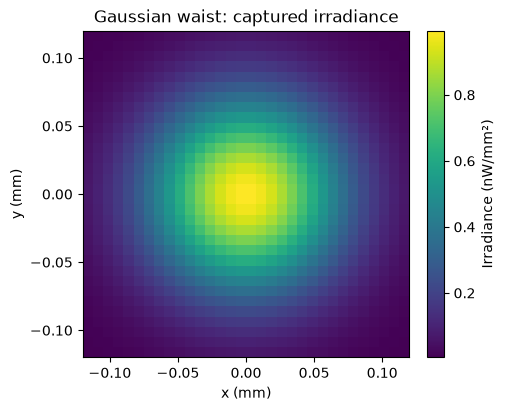

In [5]:
fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
mesh = ax.pcolormesh(
    be.to_numpy(scalar_image.x_edges_mm), be.to_numpy(scalar_image.y_edges_mm),
    be.to_numpy(scalar_image.irradiance_w_per_mm2) * 1e9, shading='flat',
)
ax.set(xlabel='x (mm)', ylabel='y (mm)', title='Gaussian waist: captured irradiance',
       aspect='equal')
fig.colorbar(mesh, ax=ax, label='Irradiance (nW/mm²)')
plt.show()